In [24]:
import os, time
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import pulp

TMAX = 600

In [25]:
OUT = "resultados_tsp"
os.makedirs(OUT, exist_ok=True)

### **Instanciación**

In [26]:
np.random.seed(100)
n = 100
x = np.random.randint(0, 1001, n)
y = np.random.randint(0, 1001, n)
coords = np.column_stack((x, y))
D = np.sqrt(((coords[:, None] - coords[None]) ** 2).sum(axis=2))

def longitud(tour):
    return sum(D[a, b] for a, b in zip(tour, tour[1:] + tour[:1]))

In [ ]:
np.savetxt(f"{OUT}/coordenadas.csv", np.column_stack((np.arange(1, n + 1), coords)),
           delimiter=",", header="nodo,x,y", comments="", fmt="%d")
np.savetxt(f"{OUT}/matriz_distancias.csv", D, delimiter=",", fmt="%.4f")

In [27]:
def graficar(tour, titulo, archivo):
    plt.figure(figsize=(8, 8))

    if tour is not None:
        t = list(tour) + [tour[0]]
        plt.plot(coords[t, 0], coords[t, 1], "r-", lw=1)

    plt.scatter(x, y, s=20)

    for i in range(n):
        plt.annotate(str(i + 1), (x[i], y[i]), fontsize=7)

    plt.title(titulo)
    plt.savefig(f"{OUT}/{archivo}", dpi=150)
    plt.show()
    plt.close()

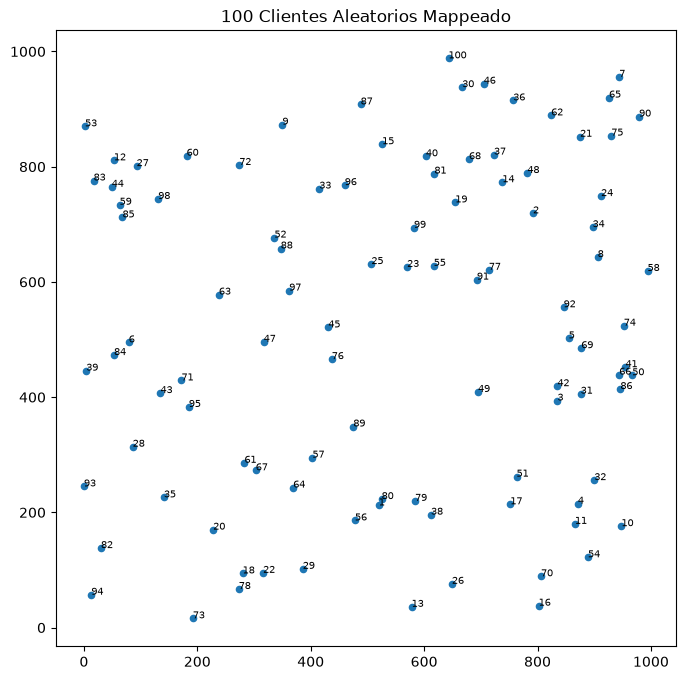

In [28]:
graficar(None, "100 Clientes Aleatorios Mappeado", "01_instancia.png")

### **Modelo Óptmimo: PuLP**

In [29]:
t0 = time.time()

arcos = [(i, j) for i in range(n) for j in range(i + 1, n)]
prob = pulp.LpProblem("TSP", pulp.LpMinimize)
xv = pulp.LpVariable.dicts("x", arcos, cat="Binary")
prob += pulp.lpSum(D[i, j] * xv[i, j] for i, j in arcos)

for k in range(n):                                                     
    prob += pulp.lpSum(xv[min(k, j), max(k, j)] for j in range(n) if j != k) == 2

LB, tour, optimo = 0, None, False

print(f"== Exacto (Tmax = {TMAX} s) ==")
while time.time() - t0 < TMAX:
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=TMAX - (time.time() - t0)))
    if prob.sol_status <= 0:                                            
        break
    opt = prob.sol_status == pulp.LpSolutionOptimal                     
    if opt:
        LB = max(LB, pulp.value(prob.objective))
    sel = [e for e in arcos if xv[e].value() > 0.5]

    vec = {i: [] for i in range(n)}
    for i, j in sel:
        vec[i].append(j)
        vec[j].append(i)
    visto, cs = set(), []
    for s in range(n):
        if s in visto:
            continue
        ciclo, prev, cur = [s], -1, s
        visto.add(s)
        while True:
            a, b = vec[cur]
            sig = a if a != prev else b
            if sig == s:
                break
            ciclo.append(sig)
            visto.add(sig)
            prev, cur = cur, sig
        cs.append(ciclo)

    if len(cs) == 1:                                                    
        tour, optimo = cs[0], opt
        break
    for ciclo in cs:                                                    
        prob += pulp.lpSum(xv[i, j] for i in ciclo for j in ciclo if i < j) <= len(ciclo) - 1
    if not opt:                                                         
        break

if tour is None:
    tour = list(range(n))

Z = longitud(tour)
if optimo:
    LB = Z
    
gap = (Z - LB) / Z * 100
t_ex = time.time() - t0

estado = "OPTIMO demostrado" if optimo else "optimalidad NO demostrada"
print(f"{estado}: Zbest={Z:.2f}  LB={LB:.2f}  Gap={gap:.3f}%  t={t_ex:.1f}s")

with open(f"{OUT}/ruta_exacta.txt", "w") as f:
    f.write(f"{estado}\nZbest={Z:.4f}  LB={LB:.4f}  Gap={gap:.4f}%  t={t_ex:.2f}s\n")
    f.write("Ruta: " + " -> ".join(str(i + 1) for i in tour + [tour[0]]) + "\n")

== Exacto (Tmax = 600 s) ==
OPTIMO demostrado: Zbest=7756.86  LB=7756.86  Gap=0.000%  t=4.1s


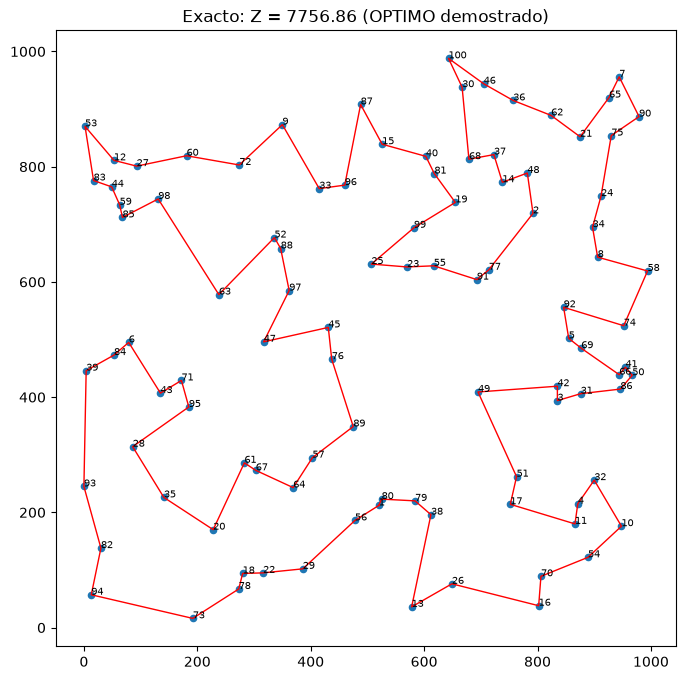

In [30]:
graficar(tour, f"Exacto: Z = {Z:.2f} ({estado})", "02_ruta_exacta.png")

### **Colonia de Hormigas**

In [ ]:
def aco(m=50, alpha=1, beta=2, rho=0.5, Q=100, n_iter=500, seed=None):
    rng = np.random.default_rng(seed)

    eta = np.zeros((n, n))
    eta[D > 0] = 1 / D[D > 0]
    tau = np.ones((n, n))

    mejor, mejor_tour, hist = np.inf, None, []
    hormigas = np.arange(m)
    t0 = time.time()

    for it in range(n_iter):
        atractivo = tau ** alpha * eta ** beta

        tours = np.zeros((m, n), dtype=int)
        sin_visitar = np.ones((m, n), dtype=bool)
        tours[:, 0] = rng.integers(n, size=m)
        sin_visitar[hormigas, tours[:, 0]] = False

        for paso in range(1, n):
            actual = tours[:, paso - 1]
            pesos = atractivo[actual] * sin_visitar
            acumulado = pesos.cumsum(axis=1)
            azar = rng.random(m) * acumulado[:, -1]
            siguiente = np.minimum((acumulado < azar[:, None]).sum(axis=1), n - 1)
            tours[:, paso] = siguiente
            sin_visitar[hormigas, siguiente] = False

        destinos = np.roll(tours, -1, axis=1)
        largos = D[tours, destinos].sum(axis=1)

        tau *= 1 - rho
        deposito = (Q / largos)[:, None]
        np.add.at(tau, (tours, destinos), deposito)
        np.add.at(tau, (destinos, tours), deposito)

        k = largos.argmin()
        if largos[k] < mejor:
            mejor, mejor_tour = largos[k], tours[k].tolist()
        hist.append(mejor)

    return dict(L=mejor, tour=mejor_tour, hist=np.array(hist), t=time.time() - t0)

In [33]:
print("\n== ACO: 10 ejecuciones ==")
runs = [aco(seed=1000 + r) for r in range(10)]
L = np.array([r["L"] for r in runs])
T = np.array([r["t"] for r in runs])
print(f"Zmin={L.min():.2f}  Zmax={L.max():.2f}  Zprom={L.mean():.2f}  "
      f"sigma={L.std(ddof=1):.2f}  t_prom={T.mean():.2f}s")


== ACO: 10 ejecuciones ==
Zmin=7982.07  Zmax=8314.39  Zprom=8145.12  sigma=88.24  t_prom=1.87s


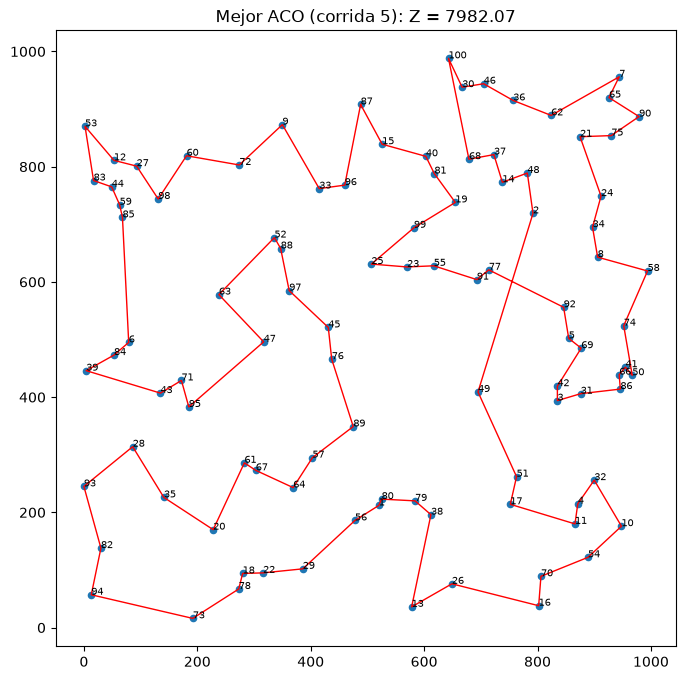

In [34]:
kb = int(L.argmin())
mejor = runs[kb]
with open(f"{OUT}/ruta_aco.txt", "w") as f:
    f.write(f"Mejor corrida: ACO {kb + 1}, Z={mejor['L']:.4f}\n")
    f.write("Ruta: " + " -> ".join(str(i + 1) for i in mejor["tour"] + [mejor["tour"][0]]) + "\n")
graficar(mejor["tour"], f"Mejor ACO (corrida {kb + 1}): Z = {mejor['L']:.2f}", "03_ruta_aco.png")

### **Comparaciones**

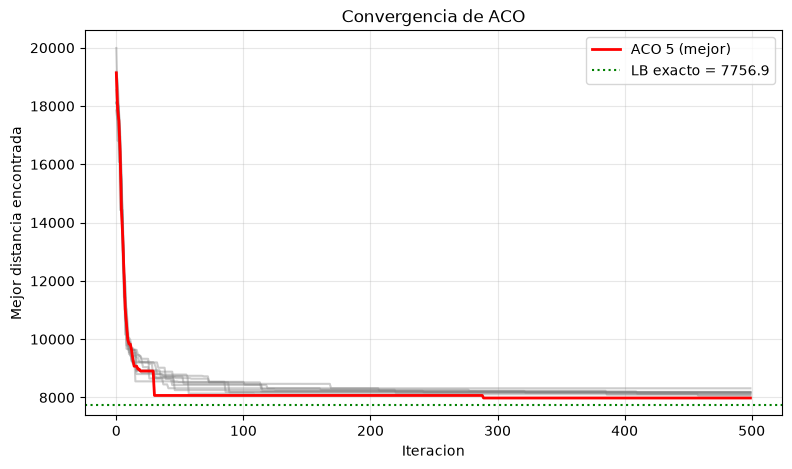

In [35]:
plt.figure(figsize=(9, 5))
for r in runs:
    plt.plot(r["hist"], color="gray", alpha=.4)
plt.plot(mejor["hist"], "r", lw=2, label=f"ACO {kb + 1} (mejor)")
plt.axhline(LB, color="g", ls=":", label=f"LB exacto = {LB:.1f}")
plt.xlabel("Iteracion"); plt.ylabel("Mejor distancia encontrada")
plt.title("Convergencia de ACO"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{OUT}/04_convergencia.png", dpi=150)
plt.show()
plt.close()

In [36]:
Zref = Z if optimo else min(Z, L.min())
print(f"\n{'Metodo':8s} {'Distancia':>10s} {'Tiempo(s)':>10s} {'Gap(%)':>8s}   (ref = {Zref:.2f})")
lineas = [f"Exacto,{Z:.2f},{t_ex:.1f},{gap:.3f}"]
print(f"{'Exacto':8s} {Z:10.2f} {t_ex:10.1f} {gap:8.3f}")
for i, r in enumerate(runs):
    gap_aco = (r["L"] - Zref) / Zref * 100
    lineas.append(f"ACO {i + 1},{r['L']:.2f},{r['t']:.2f},{gap_aco:.2f}")
    print(f"{'ACO ' + str(i + 1):8s} {r['L']:10.2f} {r['t']:10.2f} {gap_aco:8.2f}")
with open(f"{OUT}/tabla_comparacion.csv", "w") as f:
    f.write("Metodo,Mejor distancia,Tiempo (s),Gap (%)\n" + "\n".join(lineas) + "\n")


Metodo    Distancia  Tiempo(s)   Gap(%)   (ref = 7756.86)
Exacto      7756.86        4.1    0.000
ACO 1       8192.27       1.94     5.61
ACO 2       8110.92       1.96     4.56
ACO 3       8101.86       1.84     4.45
ACO 4       8179.06       1.85     5.44
ACO 5       7982.07       1.85     2.90
ACO 6       8314.39       1.87     7.19
ACO 7       8166.36       1.87     5.28
ACO 8       8180.55       1.84     5.46
ACO 9       8159.29       1.83     5.19
ACO 10      8064.43       1.88     3.97


### **Análisis de $\rho$**


== Analisis de rho (5 corridas c/u) ==
rho=0.1: mejor=8110.45 prom=8214.58 sd=79.13 t=1.94s iter_conv=262
rho=0.2: mejor=8120.82 prom=8205.21 sd=49.04 t=1.92s iter_conv=215
rho=0.3: mejor=8099.55 prom=8194.08 sd=71.51 t=1.85s iter_conv=218
rho=0.4: mejor=7971.78 prom=8133.95 sd=98.18 t=1.85s iter_conv=244
rho=0.5: mejor=8040.58 prom=8116.22 sd=63.15 t=1.83s iter_conv=244
rho=0.6: mejor=8105.85 prom=8164.76 sd=52.74 t=1.86s iter_conv=165
rho=0.7: mejor=8086.81 prom=8152.76 sd=53.95 t=1.90s iter_conv=172
rho=0.8: mejor=8066.13 prom=8118.31 sd=38.37 t=1.86s iter_conv=261
rho=0.9: mejor=8000.18 prom=8104.02 sd=72.58 t=1.86s iter_conv=198


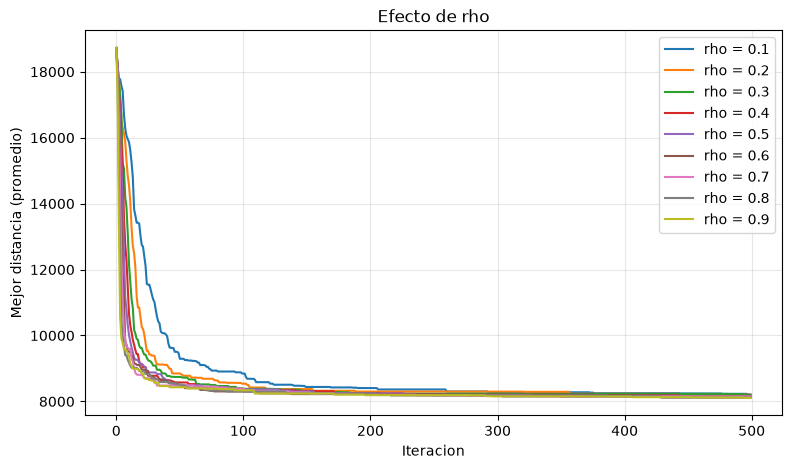

In [37]:
print("\n== Analisis de rho (5 corridas c/u) ==")
plt.figure(figsize=(9, 5))
lineas = []

for rho in [k / 10 for k in range(1, 10)]:
    rs = [aco(rho=rho, seed=5000 + i) for i in range(5)]
    l = np.array([r["L"] for r in rs])
    t = np.mean([r["t"] for r in rs])
    # iteracion en que la mejor distancia queda a <=1% del valor final
    iter_conv = np.mean([np.argmax(r["hist"] <= r["hist"][-1] * 1.01) + 1 for r in rs])
    plt.plot(np.mean([r["hist"] for r in rs], axis=0), label=f"rho = {rho}")
    print(f"rho={rho}: mejor={l.min():.2f} prom={l.mean():.2f} sd={l.std(ddof=1):.2f} "
          f"t={t:.2f}s iter_conv={iter_conv:.0f}")
    lineas.append(f"{rho},{l.min():.2f},{l.mean():.2f},{l.std(ddof=1):.2f},{t:.2f},{iter_conv:.0f}")

plt.xlabel("Iteracion"); plt.ylabel("Mejor distancia (promedio)")
plt.title("Efecto de rho"); plt.legend(); plt.grid(alpha=.3)
plt.savefig(f"{OUT}/05_analisis_rho.png", dpi=150)
plt.show()
plt.close()

with open(f"{OUT}/analisis_rho.csv", "w") as f:
    f.write("rho,mejor,promedio,desv_est,tiempo_s,iter_conv\n" + "\n".join(lineas) + "\n")

In [38]:
print(f"\nArchivos guardados en ./{OUT}/")


Archivos guardados en ./resultados_tsp/
